In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'experiments/noise_robustness/results/robustness_summary.csv').exists():
    for parent in [ROOT, *ROOT.parents]:
        if (parent / 'experiments/noise_robustness/results/robustness_summary.csv').exists():
            ROOT = parent
            break
else:
    ROOT = ROOT.resolve()
RESULTS = ROOT / 'experiments/noise_robustness/results'
assert (RESULTS / 'robustness_summary.csv').exists(), 'Run evaluate_all_methods.py first.'
print('Project root:', ROOT)

Project root: /root/lorex-ocr-llm-experiments


## 1. Summary and baseline validation

In [2]:
summary = pd.read_csv(RESULTS / 'robustness_summary.csv')
fields = pd.read_csv(RESULTS / 'robustness_per_field.csv')
assert len(summary) == 8 and (summary['n'] == 135).all()
summary['delta_f1_pp'] = summary['noisy_f1'] - summary['clean_f1']
summary['delta_exact_match_pp'] = summary['noisy_exact_match'] - summary['clean_exact_match']
cols = ['method', 'n', 'clean_exact_match', 'noisy_exact_match', 'delta_exact_match_pp', 'clean_f1', 'noisy_f1', 'delta_f1_pp']
display(summary[cols].sort_values('clean_f1', ascending=False).round(2))
print('IMPORTANT: Check clean values against the original Figure 14 before publication.')

,method,n,clean_exact_match,noisy_exact_match,delta_exact_match_pp,clean_f1,noisy_f1,delta_f1_pp
7,qwen_vlm,135,65.50,78.62,13.12,72.20,79.97,7.77
3,paddle_llm_p2,135,65.61,68.04,2.43,65.69,68.43,2.74
0,regex_tesseract,135,47.72,37.99,-9.73,52.41,42.17,-10.24
5,doctr_llm_p2,135,44.76,44.76,0.00,44.79,44.81,0.02
2,tesseract_llm_p2,135,38.73,34.60,-4.13,39.50,35.22,-4.28
1,tesseract_llm_p1,135,28.25,21.90,-6.35,30.26,23.27,-6.99
6,openocr_llm_p2,135,25.61,33.23,7.62,25.61,33.23,7.62
4,easyocr_llm_p2,135,9.95,9.63,-0.32,9.96,9.80,-0.16


IMPORTANT: Check clean values against the original Figure 14 before publication.


## 2. Clean versus noisy F1

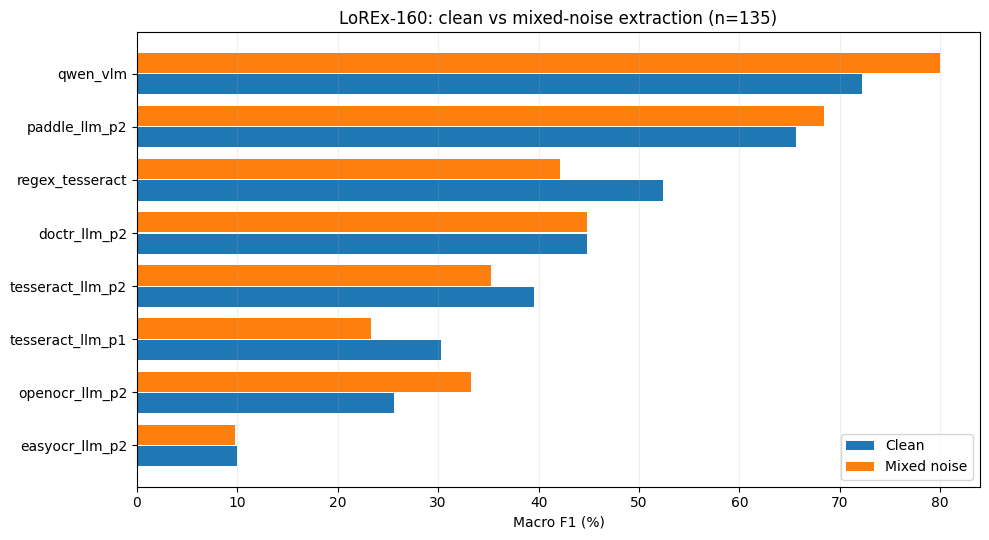

In [3]:
s = summary.sort_values('clean_f1')
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(y - .2, s['clean_f1'], height=.38, label='Clean')
ax.barh(y + .2, s['noisy_f1'], height=.38, label='Mixed noise')
ax.set_yticks(y, s['method'])
ax.set_xlabel('Macro F1 (%)')
ax.set_title('LoREx-160: clean vs mixed-noise extraction (n=135)')
ax.legend()
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(RESULTS / 'robustness_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Change in Exact Match, F1, fuzzy similarity, and Levenshtein similarity

,Exact Match,F1,Fuzzy,Levenshtein
method,,,,
regex_tesseract,-9.73,-10.24,-6.78,-6.72
tesseract_llm_p1,-6.35,-6.99,-2.31,-2.77
tesseract_llm_p2,-4.13,-4.28,-2.31,-2.70
paddle_llm_p2,2.43,2.74,-1.19,-0.97
easyocr_llm_p2,-0.32,-0.16,-4.20,-4.72
doctr_llm_p2,0.00,0.02,-1.41,-1.59
openocr_llm_p2,7.62,7.62,0.62,1.54
qwen_vlm,13.12,7.77,15.55,15.66


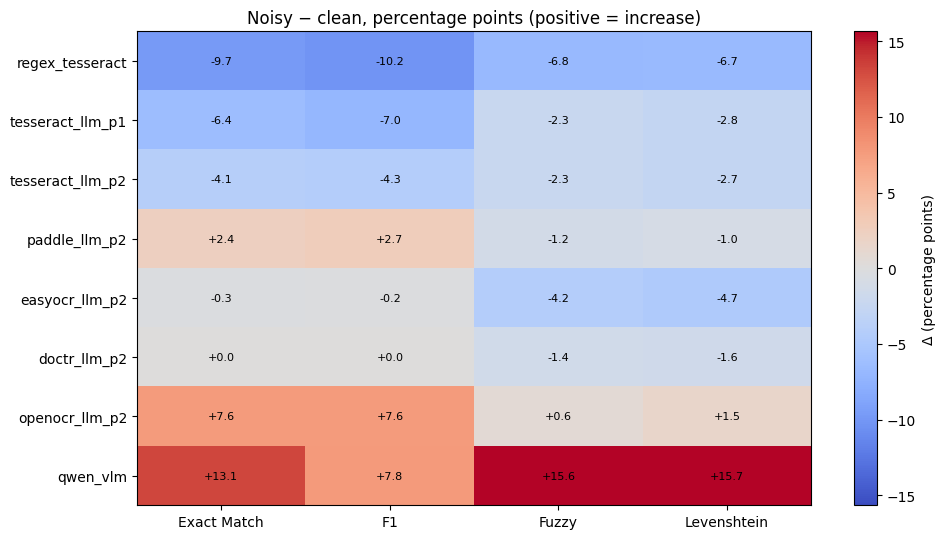

In [4]:
metrics = ['exact_match', 'f1', 'fuzzy_score', 'lev_similarity']
delta = summary.set_index('method')[[f'delta_{m}_pp' for m in metrics]]
delta.columns = ['Exact Match', 'F1', 'Fuzzy', 'Levenshtein']
display(delta.round(2))
fig, ax = plt.subplots(figsize=(10, 5.5))
heat = ax.imshow(delta.values, aspect='auto', cmap='coolwarm', vmin=-max(abs(delta.values.flatten())), vmax=max(abs(delta.values.flatten())))
ax.set_xticks(range(len(delta.columns)), delta.columns)
ax.set_yticks(range(len(delta.index)), delta.index)
for i in range(len(delta.index)):
    for j in range(len(delta.columns)):
        ax.text(j, i, f'{delta.iloc[i,j]:+.1f}', ha='center', va='center', fontsize=8)
ax.set_title('Noisy − clean, percentage points (positive = increase)')
fig.colorbar(heat, ax=ax, label='Δ (percentage points)')
fig.tight_layout()
fig.savefig(RESULTS / 'robustness_metric_delta_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Per-field robustness

field,load_number,pickup_location,pickup_time,dropoff_location,dropoff_time,total_rate,rate_per_mile
method,,,,,,,
regex_tesseract,-18.97,-4.99,-8.72,0.20,-22.20,-5.95,-11.08
tesseract_llm_p1,0.00,-4.78,-10.00,-3.59,-19.84,-3.01,-7.70
tesseract_llm_p2,-20.77,-2.96,-9.44,-5.26,-16.28,12.09,12.69
paddle_llm_p2,-4.44,0.21,-5.63,-1.26,-4.27,12.64,21.95
easyocr_llm_p2,-12.59,-0.72,0.74,2.22,0.00,8.21,0.99
doctr_llm_p2,12.59,2.96,-22.96,1.38,-21.32,11.90,15.56
openocr_llm_p2,0.00,1.48,7.41,0.74,6.67,17.78,19.26
qwen_vlm,14.64,3.83,9.74,1.54,7.15,6.35,11.09


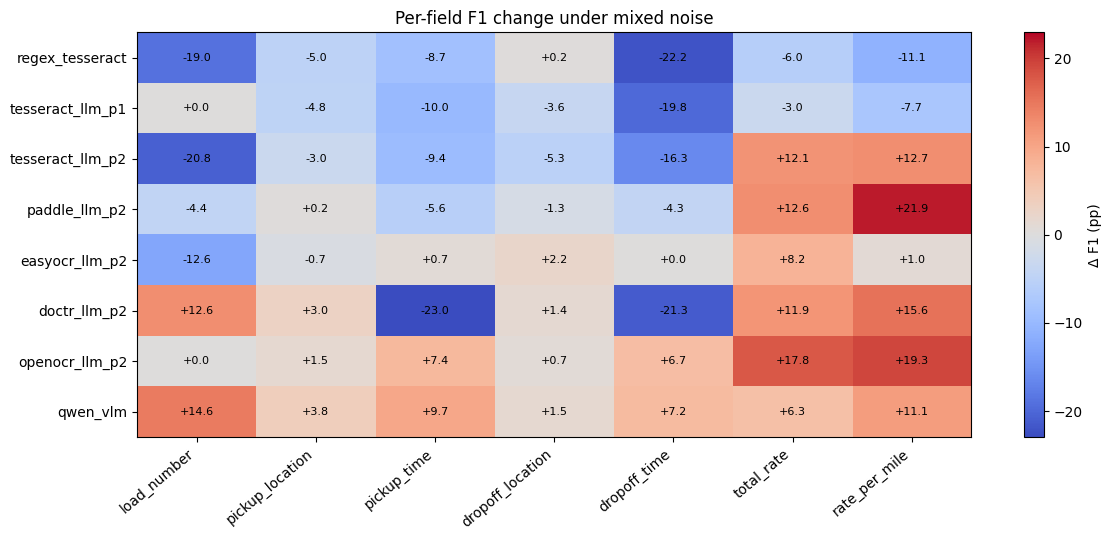

In [5]:
field_order = ['load_number', 'pickup_location', 'pickup_time', 'dropoff_location', 'dropoff_time', 'total_rate', 'rate_per_mile']
pivot = fields.pivot(index='method', columns='field', values='delta_f1_pp').reindex(index=summary['method'], columns=field_order)
display(pivot.round(2))
fig, ax = plt.subplots(figsize=(12, 5.5))
lim = max(1, np.nanmax(np.abs(pivot.values)))
im = ax.imshow(pivot.values, cmap='coolwarm', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(len(field_order)), field_order, rotation=40, ha='right')
ax.set_yticks(range(len(pivot.index)), pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f'{pivot.iloc[i,j]:+.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Δ F1 (pp)')
ax.set_title('Per-field F1 change under mixed noise')
fig.tight_layout()
fig.savefig(RESULTS / 'robustness_field_f1_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Paired document-level improvements and regressions

These counts use *exact match across seven fields* per document. They do not imply that model/provider effects have been controlled.

In [6]:
FILES = {
    'regex_tesseract': ('results/regex_tesseract_160.json', 'experiments/noise_robustness/results/regex_tesseract_mixed_135.json'),
    'tesseract_llm_p1': ('results/tesseract_llm_160.json', 'experiments/noise_robustness/results/llm/tesseract_p1_mixed_135.json'),
    'tesseract_llm_p2': ('results/tesseract_llm_160_prompt2.json', 'experiments/noise_robustness/results/llm/tesseract_p2_mixed_135.json'),
    'paddle_llm_p2': ('results/paddle_llm_160_prompt2.json', 'experiments/noise_robustness/results/llm/paddle_p2_mixed_135.json'),
    'easyocr_llm_p2': ('results/easyocr_llm_160_prompt2.json', 'experiments/noise_robustness/results/llm/easyocr_p2_mixed_135.json'),
    'doctr_llm_p2': ('results/doctr_llm_160_prompt2.json', 'experiments/noise_robustness/results/llm/doctr_p2_mixed_135.json'),
    'openocr_llm_p2': ('results/openocr_llm_160_prompt2.json', 'experiments/noise_robustness/results/llm/openocr_p2_mixed_135.json'),
    'qwen_vlm': ('results/qwen_vlm_160_clean.json', 'experiments/noise_robustness/results/qwen_vlm_mixed_135.json'),
}
F = field_order
def load_records(path):
    return json.loads((ROOT / path).read_text(encoding='utf-8'))
def record_key(r):
    return (r['split'], Path(r['source_image']).stem.lower())
def index_records(rows):
    d = {}
    for r in rows:
        k = record_key(r)
        assert k not in d, f'Duplicate: {k}'
        d[k] = r
    return d
def norm(v):
    if v is None: return None
    s = ' '.join(str(v).strip().split())
    return None if not s or s.lower() == 'null' else s

gt_rows = []
for split in ['train', 'val', 'test']:
    gt_rows += [{'split': split, **r} for r in load_records(f'data/{split}.json')]
gt = index_records(gt_rows)
ids = set(index_records(load_records('results/qwen_vlm_160_clean.json')))
assert len(ids) == 135 and ids <= set(gt)
paired = []
for method, (cp, npth) in FILES.items():
    clean, noisy = index_records(load_records(cp)), index_records(load_records(npth))
    assert ids <= set(clean) and ids <= set(noisy), method
    for k in sorted(ids):
        if noisy[k].get('_status') == 'failed':
            print('WARNING failed inference:', method, k)
        ce = sum(norm(clean[k].get(f)) == norm(gt[k].get(f)) for f in F)
        ne = sum(norm(noisy[k].get(f)) == norm(gt[k].get(f)) for f in F)
        paired.append({'method': method, 'split': k[0], 'image_id': k[1],
                       'clean_correct_fields': ce, 'noisy_correct_fields': ne,
                       'change': ne-ce})
paired = pd.DataFrame(paired)
display(paired.groupby('method')['change'].agg(
    improved=lambda x: int((x > 0).sum()),
    unchanged=lambda x: int((x == 0).sum()),
    regressed=lambda x: int((x < 0).sum()),
    mean_change='mean'
).round(2))
paired.to_csv(RESULTS / 'robustness_paired_document_changes.csv', index=False)

,improved,unchanged,regressed,mean_change
method,,,,
doctr_llm_p2,46,39,50,0.00
easyocr_llm_p2,25,80,30,-0.02
openocr_llm_p2,60,56,19,0.53
paddle_llm_p2,46,61,28,0.17
qwen_vlm,61,46,28,0.92
regex_tesseract,17,49,69,-0.68
tesseract_llm_p1,26,50,59,-0.44
tesseract_llm_p2,30,51,54,-0.29


## 6. Inspect concrete cases

In [7]:
method = 'qwen_vlm'  # change to any key in FILES
cp, npth = FILES[method]
clean, noisy = index_records(load_records(cp)), index_records(load_records(npth))
examples = paired[paired.method.eq(method)].sort_values('change', ascending=False).head(5)
for row in examples.itertuples():
    k = (row.split, row.image_id)
    print(f'\n{method} | {k} | Δ correct fields: {row.change:+d}')
    display(pd.DataFrame([{'field': f, 'ground_truth': gt[k].get(f),
                           'clean': clean[k].get(f), 'noisy': noisy[k].get(f)} for f in F]))


qwen_vlm | ('train', '23') | Δ correct fields: +7


,field,ground_truth,clean,noisy
0,load_number,1168D431H,None,1168D431H
1,pickup_location,"MKC6 KANSAS CITY, KANSAS 66102",None,"MKC6 KANSAS CITY, KANSAS 66102"
2,pickup_time,"Mon, Dec 18, 00:00 CST",None,"Mon, Dec 18, 00:00 CST"
3,dropoff_location,"MKE5 KENOSHA, WISCONSIN 53144",None,"MKE5 KENOSHA, WISCONSIN 53144"
4,dropoff_time,"Mon, Dec 18, 10:51 CST",None,"Mon, Dec 18, 10:51 CST"
5,total_rate,"$1 550,13",None,"$1 550,13"
6,rate_per_mile,$2.75/mi,None,$2.75/mi



qwen_vlm | ('train', '93') | Δ correct fields: +6


,field,ground_truth,clean,noisy
0,load_number,116WCVPQH,None,2
1,pickup_location,"MEM2 BYHALIA, MS 38611",None,"MEM2 BYHALIA, MS 38611"
2,pickup_time,"Sun, Oct 5, 12:00 CDT",None,"Sun, Oct 5, 12:00 CDT"
3,dropoff_location,"XMD4 Kenosha, WI 53142",None,"XMD4 Kenosha, WI 53142"
4,dropoff_time,"Tue, Oct 7, 01:15 CDT",None,"Tue, Oct 7, 01:15 CDT"
5,total_rate,$918.64,None,$918.64
6,rate_per_mile,$1.47/mi,None,$1.47/mi



qwen_vlm | ('train', '59') | Δ correct fields: +6


,field,ground_truth,clean,noisy
0,load_number,T-115MLCLS3,None,null
1,pickup_location,"HOU2 HOUSTON, TEXAS 77038",None,"HOU2 HOUSTON, TEXAS 77038"
2,pickup_time,"Sat, Jan 20, 11:49 CST",None,"Sat, Jan 20, 11:49 CST"
3,dropoff_location,"BNA8 LEBANON, Tennessee 37090",None,"BNA8 LEBANON, Tennessee 37090"
4,dropoff_time,"Sun, Jan 21, 07:02 CST",None,"Sun, Jan 21, 07:02 CST"
5,total_rate,"$1 475,73",None,"$1 475,73"
6,rate_per_mile,$1.71/mi,None,$1.71/mi



qwen_vlm | ('train', '20') | Δ correct fields: +6


,field,ground_truth,clean,noisy
0,load_number,113CYW4VG,None,113CYW4VG
1,pickup_location,"MCOS5 DAVENPORT, FLORIDA 33897",None,"MCOS DAVENPORT, FLORIDA 33897"
2,pickup_time,"Wed, May 1, 00:13 EDT",None,"Wed, May 1, 00:13 EDT"
3,dropoff_location,"MEM2 BYHALIA, Mississippi 38611",None,"MEM2 BYHALIA, Mississippi 38611"
4,dropoff_time,"Thu, May 2, 00:38 CDT",None,"Thu, May 2, 00:38 CDT"
5,total_rate,"$974,04",None,"$974,04"
6,rate_per_mile,$1.31/mi,None,$1.31/mi



qwen_vlm | ('train', '129') | Δ correct fields: +6


,field,ground_truth,clean,noisy
0,load_number,T-115C6F1FQ,None,null
1,pickup_location,"ATL7 UNION CITY, GA 30291",None,"ATL7 UNION CITY, GA 30291"
2,pickup_time,"Tue, Sep 30, 10:16 EDT",None,"Tue, Sep 30, 10:16 EDT"
3,dropoff_location,"RDU2 SMITHFIELD, NC 27577",None,"RDU2 SMITHFIELD, NC 27577"
4,dropoff_time,"Tue, Sep 30, 20:00 EDT",None,"Tue, Sep 30, 20:00 EDT"
5,total_rate,"$867,51",None,"$867,51"
6,rate_per_mile,$1.96/mi,None,$1.96/mi


## 7. Noise-type descriptive breakdown

Each document received **one** degradation. Differences between noise types are descriptive only because they are applied to different documents, not the same documents at all four noise types.

In [8]:
metadata = load_records('experiments/noise_robustness/noise_metadata.json')
noise_map = {record_key(r): r['noise_type'] for r in metadata}
paired['noise_type'] = [noise_map.get((r.split, r.image_id)) for r in paired.itertuples()]
assert paired['noise_type'].notna().all(), 'Metadata image IDs do not align'
display(pd.crosstab(paired['method'], paired['noise_type']))
display(paired.groupby(['method', 'noise_type'])['change'].agg(['count', 'mean']).round(2))

noise_type,blur,gaussian_noise,jpeg,rotation
method,,,,
doctr_llm_p2,34,34,34,33
easyocr_llm_p2,34,34,34,33
openocr_llm_p2,34,34,34,33
paddle_llm_p2,34,34,34,33
qwen_vlm,34,34,34,33
regex_tesseract,34,34,34,33
tesseract_llm_p1,34,34,34,33
tesseract_llm_p2,34,34,34,33


count  mean
method           noise_type                 
doctr_llm_p2     blur               34  0.38
                 gaussian_noise     34  0.26
                 jpeg               34 -0.59
                 rotation           33 -0.06
easyocr_llm_p2   blur               34 -0.29
                 gaussian_noise     34  0.15
                 jpeg               34  0.06
                 rotation           33  0.00
openocr_llm_p2   blur               34  0.29
                 gaussian_noise     34  1.44
                 jpeg               34  0.00
                 rotation           33  0.39
paddle_llm_p2    blur               34  0.03
                 gaussian_noise     34  0.15
                 jpeg               34  0.26
                 rotation           33  0.24
qwen_vlm         blur               34  1.50
                 gaussian_noise     34  0.88
                 jpeg               34  0.82
                 rotation           33  0.45
regex_tesseract  blur               34 -0.47
                 gaussian_noise     34 -0.21
                 jpeg               34 -0.47
                 rotation           33 -1.61
tesseract_llm_p1 blur               34 -0.12
                 gaussian_noise     34 -0.21
                 jpeg               34 -0.59
                 rotation           33 -0.88
tesseract_llm_p2 blur               34 -0.06
                 gaussian_noise     34 -0.09
                 jpeg               34 -0.03
                 rotation           33 -1.00